### Preparação ###

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import tensorflow as tf
from pathlib import Path
import random
import shutil
import time
import json

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense

from sklearn.metrics import classification_report, confusion_matrix

In [10]:
origem = Path("data/waste-classification-data-v2") # pasta com todos os dados
destino = Path("data/amostra") # pasta que vai armazenar as amostras (quantidade reduzidade de dados que serão utilizados para teste de forma rápida)
random.seed(42) # fixa como o embaralhamento de imagens ocorre

In [11]:
# Copia uma lista de imagens para uma outra pasta (amostra)
def copiar(arquivos, pasta):
    pasta.mkdir(parents=True, exist_ok=True)
    for f in arquivos:
        shutil.copy(f, pasta / f.name)

### Conhecendo os dados ###

In [ ]:
for split in ("TRAIN", "TEST"):
    for classe in ("N", "O", "R"):
        qtd = len(list((origem / split / classe).glob("*")))
        print(split, classe, qtd)

### Tratamento das imagens ###

In [13]:
# Define como as imagens vão ser tratadas
IMG = (160, 160) # tamanho que toda imagem vai ser redimensionada
BATCH = 32 # quantas imagens a rede vê por vez
pasta = Path("data/amostra") # pasta onde estão as amostras

# Objetos que guardam as regras de como cada imagem deve ser tratada
gen_treino = ImageDataGenerator(
    preprocessing_function=preprocess_input, # aplica o pré-processamento da MobileNetV2 em cada imagem (converte a imagem pra escala que a rede entende, -1 e 1, e não 0 e 255)
    rotation_range=20, # gira cada imagem num ângulo aleatório entre -20° e 20°  
    horizontal_flip=True # espelha a imagem na horizontal
)

# Aplica apenas o pré-processamento, pois a rotação e o espelhamento são apenas para treino
gen_avalia = ImageDataGenerator(preprocessing_function=preprocess_input)

### Amostra ###

In [12]:
# Monta as amostras
for classe in ("N", "O", "R"):
    imgs = sorted((origem / "TRAIN" / classe).glob("*")) # lista as imagens da classe e coloca em ordem (treino)
    random.shuffle(imgs) # embaralha a lista de imagens
    copiar(imgs[:400], destino / "train" / classe) # 400 primeiras imagens da lista
    copiar(imgs[400:500], destino / "val" / classe) # faixa de imagens diferente da lista (impede que as imagens de validação esteja no conjunto de imagens de treino)

    teste = sorted((origem / "TEST" / classe).glob("*")) # lista as imagens da classe e coloca em ordem (teste)
    random.shuffle(teste) # embaralha a lista de imagens
    copiar(teste[:100], destino / "test" / classe) # 100 primeiras imagens da lista

In [14]:
# Onde as imagens são de fato lidas. Retorna um gerador de lotes que entrega imagens e rótulos para a rede neural
# Um 'flow_from_directory' para cada pasta

treino = gen_treino.flow_from_directory(
    str(pasta / "train"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=True # os rótulos saem em formato de one-hot-encoding e embaralha as imagens a cada epoch para ajudar a rede a aprender (apenas no treino)
)

validacao = gen_avalia.flow_from_directory(
    str(pasta / "val"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False # os rótulos saem em formato de one-hot-encoding e não é necessário embaralhas as imagens 
)

teste = gen_avalia.flow_from_directory(
    str (pasta / "test"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False # os rótulos saem em formato de one-hot-encoding e não é necessário embaralhas as imagens
)

Found 2294 images belonging to 3 classes.
Found 595 images belonging to 3 classes.
Found 553 images belonging to 3 classes.


In [15]:
# Base já treinada
base = MobileNetV2(
    input_shape=IMG + (3,), # formato exato das imagens que vai receber (160 x 160 e 3 canais de cor (RGB))
    include_top=False, # descarta a camada final original que escolhia entre 1.000 categorias do ImageNet, trocando para a do projeto que são apenas 3
    weights="imagenet" # carrega o que a rede já aprendeu (sem isso, começaria com pesos aleatórios)
)

base.trainable = False # congela a base para fazer apenas a nova camada aprender

In [16]:
# Criando o modelo
modelo = Sequential([
    base, # base já treinada
    GlobalAveragePooling2D(), # resume o que a base extraiu num vetor de 1.280 valores, em vez de achatar tudo (Flatten)
    Dropout(0.3), # durante o treino, desliga 30% das conexões de forma aleatória, para a nova camada não decorar as imagens
    Dense(3, activation="softmax") # camada final. O 'softmax' transforma as saídas em probabilidades que somam 1
])

modelo.compile( # escolhe como a rede neural aprende
    optimizer="adam", # ajusta os pesos
    loss="categorical_crossentropy", # mede o erro 
    metrics=["accuracy"] # acurácia 
) 

modelo.summary() 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
inicio = time.time() # guardar o tempo de duração do treino

historico = modelo.fit( # treinamento do modelo
    treino, # conjunto de treino para o treinamento
    validation_data=validacao, # a cada epoch, a rede é avaliada nas imagens de validação, sem aprender com elas. O que nos confirma se a rede está de fato aprendendo e não decorando 
    epochs=5 # a rede passa pelo conjunto de treino inteiro 5 vezes
)

print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

Epoch 1/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 40s 508ms/step - accuracy: 0.6347 - loss: 0.8375 - val_accuracy: 0.7630 - val_loss: 0.5868
Epoch 2/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 20s 278ms/step - accuracy: 0.7759 - loss: 0.5443 - val_accuracy: 0.8034 - val_loss: 0.5156
Epoch 3/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 20s 280ms/step - accuracy: 0.8147 - loss: 0.4681 - val_accuracy: 0.8235 - val_loss: 0.4814
Epoch 4/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 21s 286ms/step - accuracy: 0.8282 - loss: 0.4336 - val_accuracy: 0.8235 - val_loss: 0.4687
Epoch 5/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 20s 274ms/step - accuracy: 0.8374 - loss: 0.3915 - val_accuracy: 0.8403 - val_loss: 0.4348
Tempo total: 2.0 min


In [18]:
# Mostra onde a rede acerta e onde erra, classe por classe
validacao.reset() # faz o gerador voltar para a primeira imagem para alinhar os rótulos
prob = modelo.predict(validacao) # retorna a probabilidade de classe para cada imagem
previsto = np.argmax(prob, axis=1) # escolhe a classe de maior probabilidade
real = validacao.classes # rótulo real
nomes = list(validacao.class_indices) # nomes das classes para mostrar o nome e não o número no relatório

print(classification_report(real, previsto, target_names=nomes))
print(confusion_matrix(real, previsto))

19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 214ms/step
              precision    recall  f1-score   support

           N       0.84      0.85      0.84       196
           O       0.91      0.88      0.90       199
           R       0.78      0.79      0.78       200

    accuracy                           0.84       595
   macro avg       0.84      0.84      0.84       595
weighted avg       0.84      0.84      0.84       595

[[166   4  26]
 [  4 176  19]
 [ 28  14 158]]


In [19]:
# Acha quais imagens a rede errou de um jeito específico
caminhos = validacao.filepaths # lista de caminho das imagens
iR, iN = nomes.index("R"), nomes.index("N") # descobre o número de cada classe  
erros = [i for i in range(len(real)) if real[i] == iR and previsto[i] == iN] # percorre todos as posições 'i' e guarda só as que a previsão foi 'N' e a classe real é 'R'

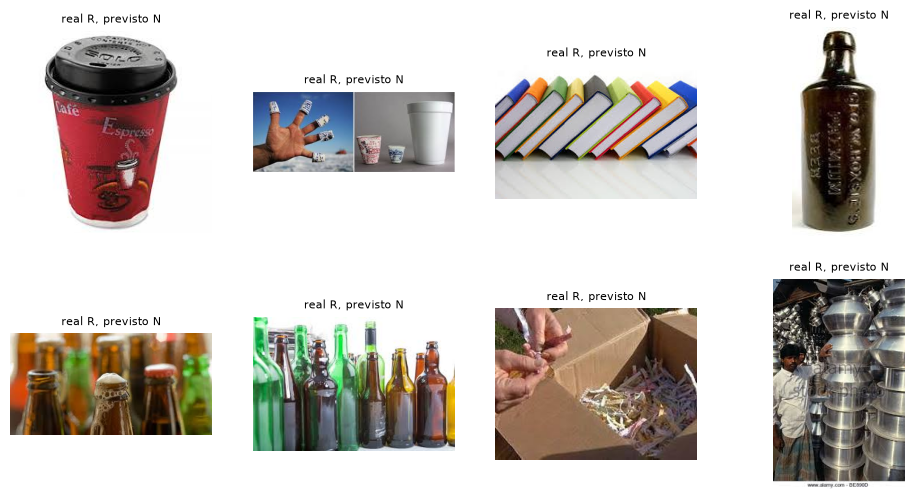

In [20]:
# Mostra as imagens da célula acima
fig, eixos = plt.subplots(2, 4, figsize=(12, 6)) # 
for ax, i in zip(eixos.flat, erros[:8]):
    ax.imshow(mpimg.imread(caminhos[i]))
    ax.set_title("real R, previsto N", fontsize=8)
    ax.axis("off")
plt.show()

In [21]:
# Fine-tuning
base.trainable = True # libera a base inteira

for camada in base.layers[:-30]:
    camada.trainable = False # congela tudo menos as 30 últimas camadas

modelo.compile( # só aplica a mudança de 'trainable' depois de uma nova compilação
    optimizer=tf.keras.optimizers.Adam( # algoritmo que decide como mudar os pesos a cada lote, com base no erro
        learning_rate=1e-5 # tamanho do passo que o otimizador dá em cada ajuste (muito pequeno porque camadas liberadas já tem bons pesos, e um passo grande estragaria esse aprendizado)
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

historico_ft = modelo.fit( # treina novamente o modelo, agora com as camadas liberadas
    treino, 
    validation_data=validacao, 
    epochs=5
)

Epoch 1/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 32s 360ms/step - accuracy: 0.7934 - loss: 0.4972 - val_accuracy: 0.8387 - val_loss: 0.4451
Epoch 2/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 24s 337ms/step - accuracy: 0.8313 - loss: 0.4285 - val_accuracy: 0.8403 - val_loss: 0.4489
Epoch 3/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 353ms/step - accuracy: 0.8348 - loss: 0.4152 - val_accuracy: 0.8387 - val_loss: 0.4496
Epoch 4/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 341ms/step - accuracy: 0.8448 - loss: 0.3772 - val_accuracy: 0.8387 - val_loss: 0.4436
Epoch 5/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 25s 340ms/step - accuracy: 0.8575 - loss: 0.3725 - val_accuracy: 0.8387 - val_loss: 0.4335


### Dataset completo ###

In [22]:
# Preparando o dataset inteiro para treino
random.seed(42) 
destino_completo = Path("data/completo")

for classe in ("N", "O", "R"): 
    imgs = sorted((origem / "TRAIN" / classe).glob("*"))
    random.shuffle(imgs)
    corte = int(len(imgs) * 0.85)
    copiar(imgs[:corte], destino_completo / "train" / classe)
    copiar(imgs[corte:], destino_completo / "val" / classe)

In [23]:
# Célula que cria o dataset completo
for split in ("train", "val"):
    for classe in ("N", "O", "R"):
        qtd = len(list((destino_completo / split / classe).glob("*")))
        print(split, classe, qtd)

train N 2419
train O 10680
train R 6079
val N 428
val O 1885
val R 1073


In [24]:
pasta_completo = Path("data/completo")
pasta_teste = origem / "TEST"

In [ ]:
# Aplicando os generators nos conjuntos do dataset completo
treino_c = gen_treino.flow_from_directory(
    str(pasta_completo / "train"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=True
)

validacao_c = gen_avalia.flow_from_directory(
    str(pasta_completo / "val"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False
)

teste_c = gen_avalia.flow_from_directory(
    str(pasta_teste / "val"), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False
)

Found 19178 images belonging to 3 classes.
Found 3386 images belonging to 3 classes.
Found 3386 images belonging to 3 classes.


In [26]:
# Calcula um peso por classe, para compensar o desbalanceamento. 'N' é apenas 12,6% das imagens, e sem a compensação a rede tende a ignorá-la, por que errar nela custa pouco na média
contagem = np.bincount(treino_c.classes) # conta quantas vezes cada número (rótulo) aparece
pesos = {i: len(treino_c.classes) / (len(contagem) * c) for i, c in enumerate(contagem)} # fórmula do peso
print(treino_c.class_indices)
print(pesos)

{'N': 0, 'O': 1, 'R': 2}
{0: np.float64(2.6426898167286756), 1: np.float64(0.5985642946317103), 2: np.float64(1.0515983988594615)}


In [27]:
# Montando o novo modelo pro dataset completo
base = MobileNetV2(
    input_shape=IMG + (3,), 
    include_top=False, 
    weights="imagenet"
)

base.trainable = False

modelo_c = Sequential([
    base, 
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(3, activation="softmax")
])

In [28]:
modelo_c.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

inicio = time.time()
historico_c =  modelo_c.fit(
    treino_c, validation_data=validacao_c, epochs=5, class_weight=pesos
)

print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

Epoch 1/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 445s 733ms/step - accuracy: 0.7903 - loss: 0.5831 - val_accuracy: 0.8302 - val_loss: 0.4374
Epoch 2/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 195s 324ms/step - accuracy: 0.8435 - loss: 0.4535 - val_accuracy: 0.8621 - val_loss: 0.3683
Epoch 3/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 202s 336ms/step - accuracy: 0.8524 - loss: 0.4336 - val_accuracy: 0.8523 - val_loss: 0.3927
Epoch 4/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 202s 336ms/step - accuracy: 0.8538 - loss: 0.4264 - val_accuracy: 0.8783 - val_loss: 0.3167
Epoch 5/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 192s 320ms/step - accuracy: 0.8477 - loss: 0.4346 - val_accuracy: 0.8506 - val_loss: 0.3860
Tempo total: 20.6 min


In [29]:
validacao_c.reset()
prob_c = modelo_c.predict(validacao_c)
previsto_c = np.argmax(prob_c, axis=1)
real_c = validacao_c.classes
nomes_c = list(validacao_c.class_indices)

print(classification_report(real_c, previsto_c, target_names=nomes_c))
print(confusion_matrix(real_c, previsto_c))

106/106 ━━━━━━━━━━━━━━━━━━━━ 20s 176ms/step
              precision    recall  f1-score   support

           N       0.53      0.90      0.67       428
           O       0.98      0.88      0.93      1885
           R       0.86      0.78      0.82      1073

    accuracy                           0.85      3386
   macro avg       0.79      0.85      0.81      3386
weighted avg       0.89      0.85      0.86      3386

[[ 387   10   31]
 [ 131 1653  101]
 [ 210   23  840]]


In [30]:
w = np.array([pesos[i] for i in range(3)])
prob_ajustada = prob_c / w
previsto_aj = np.argmax(prob_ajustada, axis=1)

print(classification_report(real_c, previsto_aj, target_names=nomes_c))
print(confusion_matrix(real_c, previsto_aj))

              precision    recall  f1-score   support

           N       0.67      0.82      0.74       428
           O       0.96      0.93      0.95      1885
           R       0.86      0.84      0.85      1073

    accuracy                           0.89      3386
   macro avg       0.83      0.87      0.85      3386
weighted avg       0.90      0.89      0.89      3386

[[ 353   18   57]
 [  45 1756   84]
 [ 125   47  901]]


In [32]:
Path("modelos").mkdir(exist_ok=True)
modelo_c.save("modelos/modelo_c_fase1.keras")

base_c = modelo_c.layers[0]
base_c.trainable = True
for camada in base_c.layers[:-30]:
    camada.trainable = False
for camada in base_c.layers[-30:]:
    if isinstance(camada, tf.keras.layers.BatchNormalization):
        camada.trainable = False

modelo_c.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "modelos/modelo_c_fase2.keras", monitor="val_accuracy", save_best_only=True
)

inicio = time.time()
historico_c_ft = modelo_c.fit(
    treino_c, validation_data=validacao_c, epochs=5,
    class_weight=pesos, callbacks=[checkpoint]
)

print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min ")

Epoch 1/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 212s 347ms/step - accuracy: 0.8661 - loss: 0.3810 - val_accuracy: 0.8937 - val_loss: 0.2722
Epoch 2/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 234s 390ms/step - accuracy: 0.8889 - loss: 0.3221 - val_accuracy: 0.8887 - val_loss: 0.2882
Epoch 3/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 228s 380ms/step - accuracy: 0.8982 - loss: 0.2950 - val_accuracy: 0.9084 - val_loss: 0.2433
Epoch 4/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 206s 343ms/step - accuracy: 0.9079 - loss: 0.2603 - val_accuracy: 0.8940 - val_loss: 0.2763
Epoch 5/5
600/600 ━━━━━━━━━━━━━━━━━━━━ 219s 365ms/step - accuracy: 0.9140 - loss: 0.2472 - val_accuracy: 0.9014 - val_loss: 0.2553
Tempo total: 18.3 min 


In [34]:
modelo_ft = tf.keras.models.load_model("modelos/modelo_c_fase2.keras")

validacao_c.reset() 
prob_ft = modelo_ft.predict(validacao_c)
real_ft = validacao_c.classes
nomes_ft = list(validacao_c.class_indices)

previsto_ft = np.argmax(prob_ft, axis=1)
print(classification_report(real_ft, previsto_ft, target_names=nomes_ft))
print(confusion_matrix(real_ft, previsto_ft))

w = np.array([pesos[i] for i in range(3)])
previsto_ft_aj = np.argmax(prob_ft / w, axis=1)
print(classification_report(real_ft, previsto_ft_aj, target_names=nomes_ft))
print(confusion_matrix(real_ft, previsto_ft_aj))

106/106 ━━━━━━━━━━━━━━━━━━━━ 22s 197ms/step
              precision    recall  f1-score   support

           N       0.72      0.87      0.79       428
           O       0.98      0.93      0.95      1885
           R       0.88      0.89      0.88      1073

    accuracy                           0.91      3386
   macro avg       0.86      0.90      0.88      3386
weighted avg       0.92      0.91      0.91      3386

[[ 373   12   43]
 [  45 1753   87]
 [ 101   22  950]]
              precision    recall  f1-score   support

           N       0.83      0.78      0.80       428
           O       0.96      0.96      0.96      1885
           R       0.88      0.91      0.89      1073

    accuracy                           0.92      3386
   macro avg       0.89      0.88      0.89      3386
weighted avg       0.92      0.92      0.92      3386

[[ 334   26   68]
 [  16 1802   67]
 [  53   45  975]]


In [37]:
teste_c.reset()
prob_t = modelo_ft.predict(teste_c)
real_t = teste_c.classes
nomes_t = list(teste_c.class_indices)

usar_ajuste = False
w = np.array([pesos[i] for i in range(3)])
previsto_t = np.argmax(prob_t / w if usar_ajuste else prob_t, axis=1)

print(classification_report(real_t, previsto_t, target_names=nomes_t))
print(confusion_matrix(real_t, previsto_t))

91/91 ━━━━━━━━━━━━━━━━━━━━ 36s 393ms/step
              precision    recall  f1-score   support

           N       0.48      0.81      0.60       394
           O       0.88      0.97      0.92      1401
           R       0.86      0.54      0.66      1112

    accuracy                           0.78      2907
   macro avg       0.74      0.77      0.73      2907
weighted avg       0.82      0.78      0.78      2907

[[ 319    7   68]
 [  13 1357   31]
 [ 335  174  603]]


In [36]:
pasta_teste = origem / "TEST"

teste_c = gen_avalia.flow_from_directory(
    str(pasta_teste), target_size=IMG, batch_size=BATCH,
    class_mode="categorical", shuffle=False
)

print(teste_c.directory)
print(teste_c.class_indices)

Found 2907 images belonging to 3 classes.
data\waste-classification-data-v2\TEST
{'N': 0, 'O': 1, 'R': 2}


R previsto como N:  335


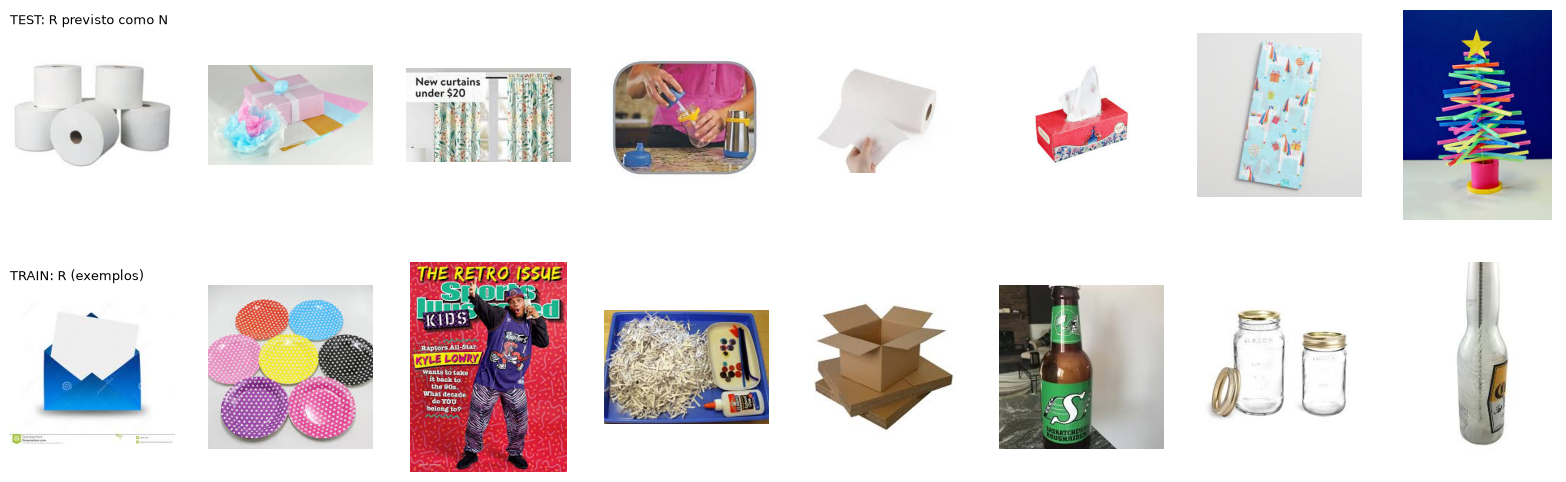

In [38]:
iR, iN = nomes_t.index("R"), nomes_t.index("N")
erros_t = [i for i in range(len(real_t)) if real_t[i] == iR and previsto_t[i] == iN]
print("R previsto como N: ", len(erros_t))

random.seed(0)
amostra_erros = random.sample(erros_t, 8)

treino_R = sorted((origem / "TRAIN" / "R").glob("*"))
amostra_treino = random.sample(treino_R, 8)

fig, eixos = plt.subplots(2, 8, figsize=(20, 6))
for ax, i in zip(eixos[0], amostra_erros):
    ax.imshow(mpimg.imread(teste_c.filepaths[i]))
    ax.axis("off")
eixos[0][0].set_title("TEST: R previsto como N", loc="left", fontsize=9)
for ax, caminho in zip(eixos[1], amostra_treino):
    ax.imshow(mpimg.imread(caminho))
    ax.axis("off")
eixos[1][0].set_title("TRAIN: R (exemplos)", loc="left", fontsize=9)
plt.show()

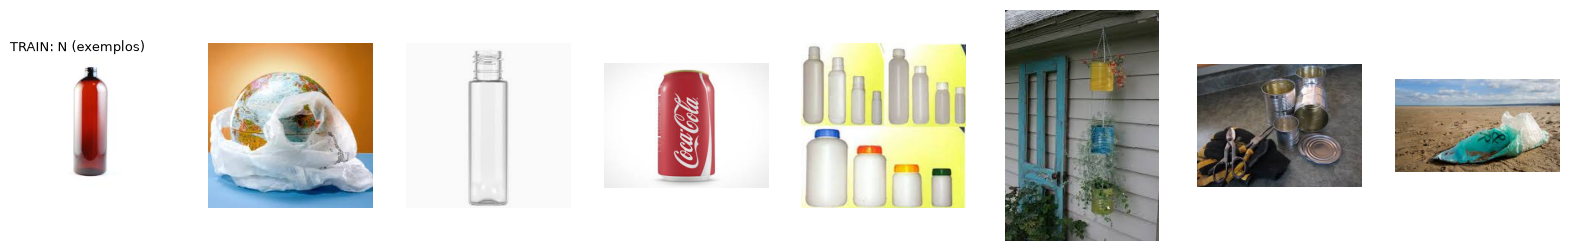

In [40]:
random.seed(1)
treino_N = sorted((origem / "TRAIN" / "N").glob("*"))
amostra_N = random.sample(treino_N, 8)

fig, eixos = plt.subplots(1, 8, figsize=(20, 3))
for ax, caminho in zip(eixos, amostra_N):
    ax.imshow(mpimg.imread(caminho))
    ax.axis("off")
eixos[0].set_title("TRAIN: N (exemplos)", loc="left", fontsize=9)
plt.show()

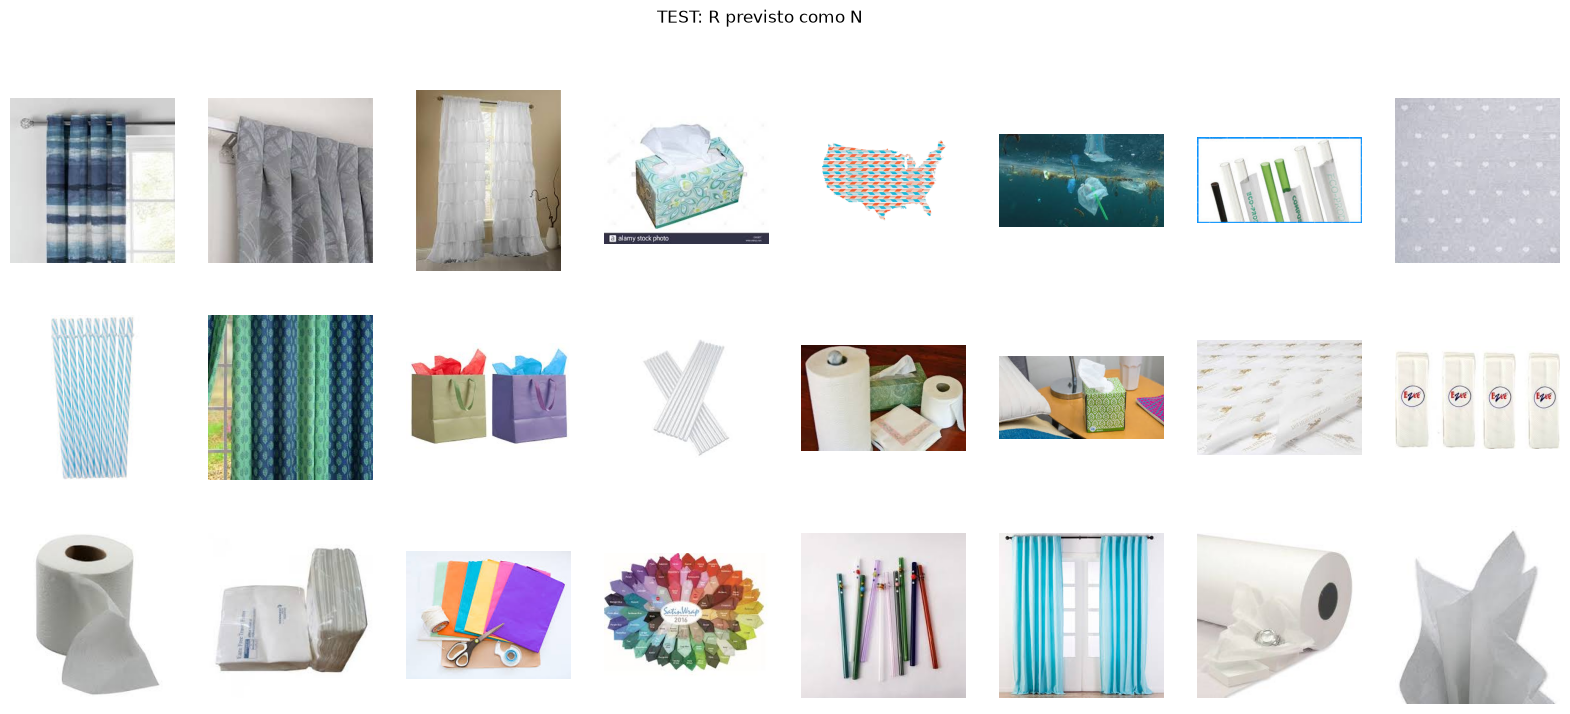

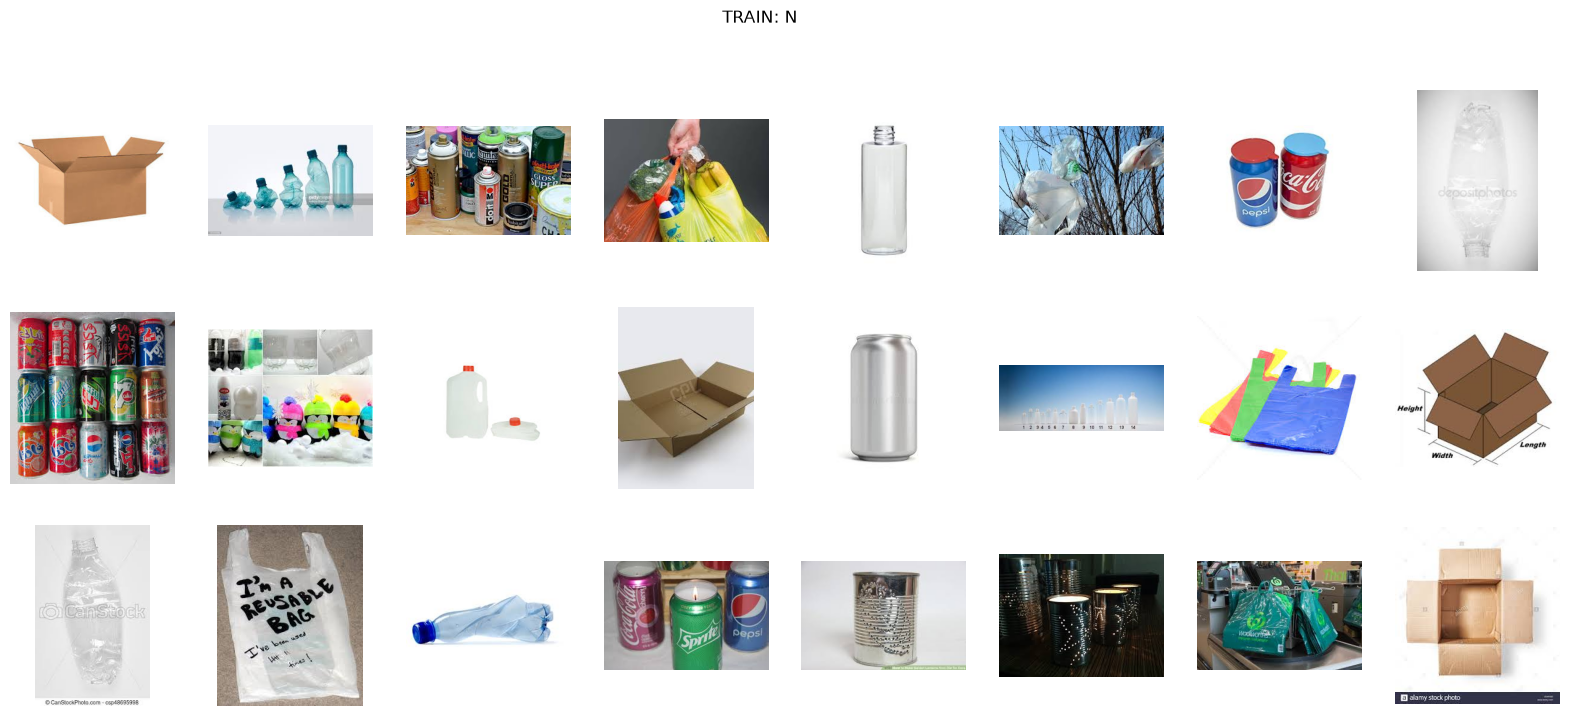

In [41]:
def mostrar(caminhos, titulo, n=24):
    fig, eixos = plt.subplots(3, 8, figsize=(20, 8))
    for ax, c in zip(eixos.flat, caminhos[:n]):
        ax.imshow(mpimg.imread(c))
        ax.axis("off")
    fig.suptitle(titulo)
    plt.show()

random.seed(2)
mostrar([teste_c.filepaths[i] for i in random.sample(erros_t, 24)], "TEST: R previsto como N")
mostrar(random.sample(treino_N, 24), "TRAIN: N")